# Прогноз травм спортсменов по данным носимых датчиков

## 0. Постановка задачи

Датасет [Multimodal Sports Injury Prediction](https://www.kaggle.com/datasets/anjalibhegam/multimodal-sports-injury-dataset) (Kaggle) содержит 15 420 записей о тренировках 156 спортсменов за полгода наблюдений. Каждая запись - одна тренировка, для которой известны:

- **физиология**: пульс, температура тела, гидратация, качество сна, показатель восстановления, уровень стресса
- **биомеханика**: активность мышц (ЭМГ), углы в суставах, скорость ходьбы, каденс, число шагов, высота прыжка, сила реакции опоры, амплитуда движений
- **условия**: температура воздуха, влажность, высота над уровнем моря, тип покрытия
- **нагрузка**: интенсивность (RPE), длительность, тренировочная нагрузка (training load), индекс усталости
- **данные о спортсмене**: вид спорта, пол, возраст, ИМТ (индекс массы тела)

Целевой признак `injury_occurred` описывает состояние спортсмена после сессии:
`0` - здоров (Healthy), `1` - повышенный риск (Low Risk), `2` - травма произошла или неизбежна (Injured).

Это задача **многоклассовой классификации** по трем классам, причем классы несбалансированы (64/21/15). Практический смысл: научиться прогнозировать риск травмы по состояниию спортсмена и варьировать его нагрузку на основе предсказанного риска.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Чтение данных

In [39]:
import os
import kagglehub

path = kagglehub.dataset_download("anjalibhegam/multimodal-sports-injury-dataset")

print(path)
os.listdir(path)

C:\Users\Reptilia\.cache\kagglehub\datasets\anjalibhegam\multimodal-sports-injury-dataset\versions\2


['multimodal_sports_injury_dataset.csv', 'README.md']

In [40]:
data_raw = pd.read_csv(os.path.join(path, 'multimodal_sports_injury_dataset.csv'))
data_raw.shape

(15420, 29)

In [41]:
data_raw.head()

,athlete_id,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,...,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,session_id,sport_type,gender,age,bmi
0,1,NaN,37.048668,76.481477,5.466370,77.899691,0.375825,10.000000,126.480118,2.654327,...,5.678475,79.106564,548.417962,45.028687,0,1,Basketball,Female,18,25.105748
1,1,40.000000,36.929536,72.363938,6.899090,74.845323,0.279165,310.293156,157.631630,3.431107,...,NaN,116.954654,538.043815,42.254717,2,2,Basketball,Female,18,25.105748
2,1,76.174609,36.334841,100.000000,9.574152,83.538316,0.334061,158.659094,81.766287,0.800000,...,6.643242,96.354742,647.784339,61.870056,0,3,Basketball,Female,18,25.105748
3,1,100.543724,37.244474,86.172473,7.614297,79.966618,0.218766,107.079298,113.023701,1.713869,...,6.194427,97.619130,336.553431,50.268845,0,4,Basketball,Female,18,25.105748
4,1,78.001235,36.510766,83.195889,5.631979,56.945979,0.484086,164.347133,112.814695,2.154233,...,5.835804,83.155527,496.076352,29.233575,2,5,Basketball,Female,18,25.105748


In [42]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   athlete_id             15420 non-null  int64  
 1   heart_rate             15066 non-null  float64
 2   body_temperature       15420 non-null  float64
 3   hydration_level        15035 non-null  float64
 4   sleep_quality          14927 non-null  float64
 5   recovery_score         15420 non-null  float64
 6   stress_level           15420 non-null  float64
 7   muscle_activity        14850 non-null  float64
 8   joint_angles           15420 non-null  float64
 9   gait_speed             14989 non-null  float64
 10  cadence                15420 non-null  float64
 11  step_count             15420 non-null  int64  
 12  jump_height            15420 non-null  float64
 13  ground_reaction_force  15420 non-null  float64
 14  range_of_motion        15420 non-null  float64
 15  ambient_tempe

Большинство признаков количественные. Исключения:

- `sport_type` - номинальный
- `gender` - номинальный / бинарный
- `playing_surface` - номинальный
- `athlete_id`, `session_id` - идентификаторы

In [43]:
data_raw['sport_type'] = data_raw['sport_type'].astype('category')
data_raw['gender'] = data_raw['gender'].astype('category')
data_raw['playing_surface'] = data_raw['playing_surface'].astype('category')

data = data_raw.drop(['athlete_id', 'session_id'], axis=1)

data.describe()

,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,cadence,...,ambient_temperature,humidity,altitude,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,age,bmi
count,15066.000000,15420.000000,15035.000000,14927.000000,15420.000000,15420.000000,14850.000000,15420.000000,14989.000000,15420.000000,...,15420.000000,15420.000000,15420.000000,14788.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000
mean,72.688277,37.106443,78.036991,5.817429,55.202220,0.422916,247.724105,112.464607,1.864699,86.803006,...,24.898073,58.191697,297.357416,6.399174,87.790419,670.534269,59.698315,0.510117,23.953567,23.138679
std,17.758991,0.594843,11.848363,1.814602,17.326338,0.173425,126.930007,30.367148,0.603927,24.296357,...,5.095228,13.526094,212.351977,1.730882,27.628191,328.288466,25.196238,0.741662,3.883533,2.301192
min,40.000000,35.800000,45.000000,1.155807,8.902584,0.100000,10.000000,45.000000,0.800000,50.000000,...,15.000000,30.000000,0.000000,2.000000,30.000000,150.000000,15.000000,0.000000,18.000000,18.500000
25%,60.097967,36.698612,69.879145,4.510581,42.321722,0.300472,159.150375,91.437246,1.430372,68.051911,...,21.254558,48.605990,127.750679,5.208488,68.768634,426.148857,41.717110,0.000000,21.000000,21.609635
50%,72.304051,37.107090,78.165927,5.755650,54.421403,0.421168,245.496682,112.548535,1.854269,85.716003,...,24.839380,58.206251,284.172663,6.411926,87.835380,645.225337,57.340187,0.000000,24.000000,22.988013
75%,84.812895,37.512165,86.498440,7.068894,67.375690,0.543678,334.039698,133.960070,2.281691,103.378064,...,28.397207,67.872637,442.388486,7.597567,106.696365,879.607967,75.186924,1.000000,27.000000,24.817666
max,159.270125,39.200000,100.000000,10.000000,98.000000,0.950000,722.542819,175.000000,3.500000,185.943983,...,38.000000,85.000000,1200.000000,10.000000,180.000000,2632.637547,270.193219,2.000000,34.000000,28.300000


## 2. Обучающая и тестовая выборки

Разбиение 75/25

In [44]:
from sklearn.model_selection import train_test_split

X = data.drop('injury_occurred', axis=1)
y = data['injury_occurred']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

X_train.shape, X_test.shape

((11565, 26), (3855, 26))

In [45]:
pd.DataFrame({'train': y_train.value_counts(normalize=True),
              'test':  y_test.value_counts(normalize=True)}).round(3)

,train,test
injury_occurred,,
0,0.64,0.64
1,0.21,0.21
2,0.15,0.15


## 3. Основные характеристики

In [46]:
train = X_train.copy()
train['injury_occurred'] = y_train
train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
heart_rate,11302.0,72.73,17.82,40.00,60.07,72.41,84.88,137.99
body_temperature,11565.0,37.11,0.60,35.80,36.70,37.11,37.51,39.20
hydration_level,11272.0,78.15,11.81,45.00,70.05,78.23,86.60,100.00
sleep_quality,11191.0,5.80,1.80,1.16,4.51,5.75,7.05,10.00
recovery_score,11565.0,55.16,17.29,9.54,42.36,54.36,67.22,98.00
stress_level,11565.0,0.42,0.17,0.10,0.30,0.42,0.54,0.95
muscle_activity,11143.0,248.62,127.46,10.00,159.42,246.17,335.24,722.54
joint_angles,11565.0,112.62,30.40,45.00,91.39,112.70,134.04,175.00
gait_speed,11241.0,1.86,0.60,0.80,1.43,1.85,2.28,3.50
cadence,11565.0,86.73,24.14,50.00,68.13,85.85,103.18,185.94


- Средние и медианы почти везде совпадают, то есть распределения в целом симметричны. Исключения - `fatigue_index` и `training_load` (среднее больше медианы, правый хвост)
- По `count` видно, что в шести признаках есть пропуски

([<matplotlib.axis.XTick at 0x20b4d02a0d0>,
 [Text(0, 0, '0: Healthy'),
  Text(1, 0, '1: Low Risk'),
  Text(2, 0, '2: Injured')])

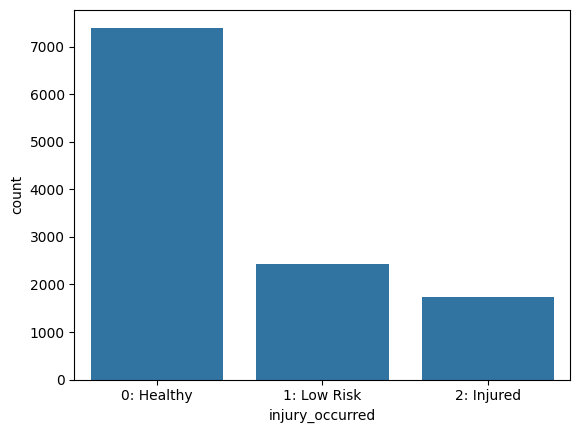

In [47]:
sns.countplot(x='injury_occurred', data=train)
plt.xticks([0, 1, 2], ['0: Healthy', '1: Low Risk', '2: Injured'])

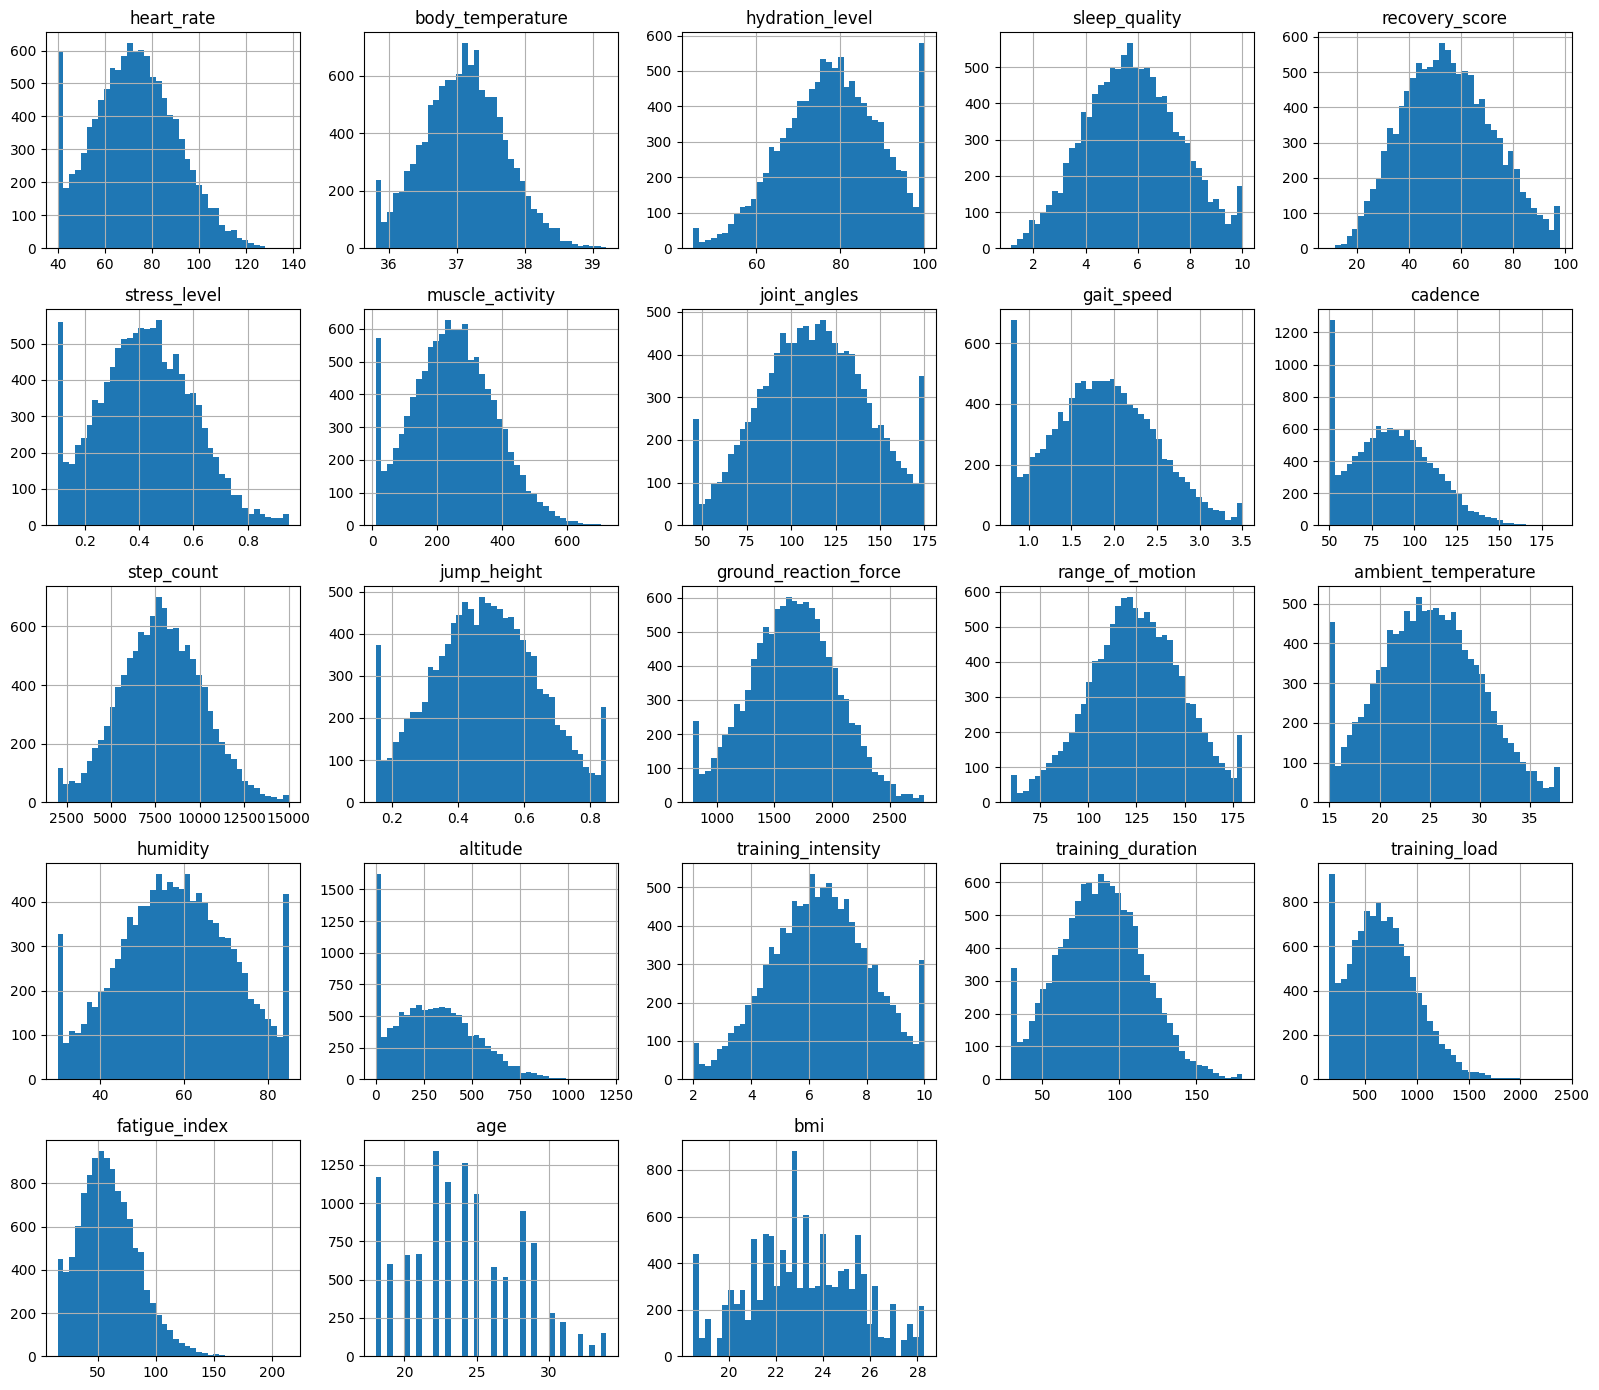

In [48]:
train.select_dtypes('number').drop('injury_occurred', axis=1).hist(bins=40, figsize=(16, 14))
plt.tight_layout()


- судя по всему, данные обрезаны по некоторому допустимому диапазону, отброшенные значения записаны в концы отрезков (видно из высоких граничных столбцов)
- `fatigue_index` и `training_load` скошены вправо
- гистограммы `age` и `bmi` зубчатые, потому что это характеристики 156 спортсменов, которые многократно повторяются

<Axes: >

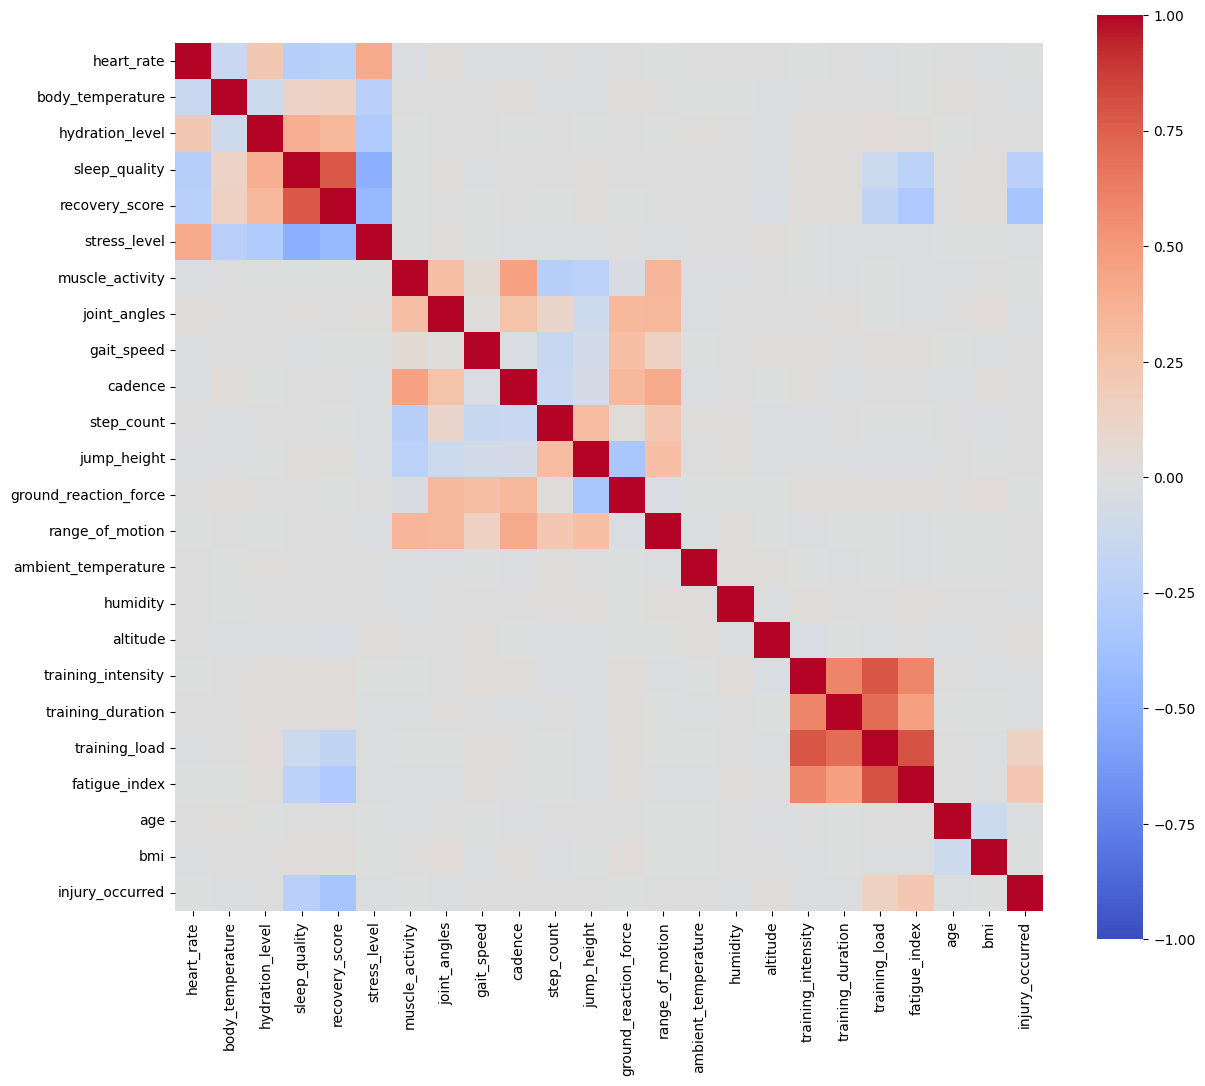

In [49]:
corr_mat = train.corr(numeric_only=True)

plt.figure(figsize=(14, 12))
sns.heatmap(corr_mat, square=True, vmin=-1, vmax=1, cmap='coolwarm')

In [50]:
corr_mat.where(np.triu(np.abs(corr_mat) > 0.3, k=1)).stack().dropna().sort_values(ascending=False)

training_load       fatigue_index            0.800953
training_intensity  training_load            0.788198
sleep_quality       recovery_score           0.773866
training_duration   training_load            0.698636
training_intensity  training_duration        0.595241
                    fatigue_index            0.590082
training_duration   fatigue_index            0.461484
muscle_activity     cadence                  0.456871
cadence             range_of_motion          0.418202
heart_rate          stress_level             0.410551
hydration_level     sleep_quality            0.384565
muscle_activity     range_of_motion          0.348184
joint_angles        range_of_motion          0.342495
hydration_level     recovery_score           0.332534
cadence             ground_reaction_force    0.330306
joint_angles        ground_reaction_force    0.328889
step_count          jump_height              0.308897
recovery_score      fatigue_index           -0.319624
jump_height         ground_r

Признаки существенно связаны внутри своих групп, межгрупповая связь слаба:

- **нагрузка**: `training_load` ≈ интенсивность × длительность, сильно коррелирует с обоими признаками (0.79 и 0.70), а также с `fatigue_index` (0.80): больше нагрузка - больше усталость
- **физиология**: `recovery_score` и `sleep_quality` (0.77) - хорошо выспался, лучше восстановился. Стресс отрицательно связан со сном и восстановлением (−0.50, −0.43) и положительно - с пульсом (0.41)
- **биомеханика**: умеренные связи между активностью мышц, каденсом, амплитудой движений, силой реакции опоры (0.3–0.46)

Связи физически осмысленные. Из группы нагрузки видно, что `training_load` во многом дублирует интенсивность и длительность.

Проверим связи с целевым признаком:

Text(0.5, 0, 'корреляция с injury_occurred')

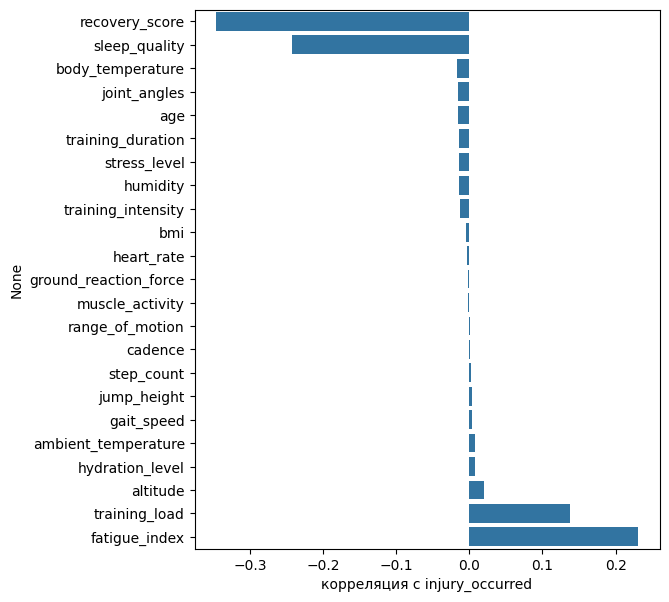

In [51]:
target_corr = corr_mat['injury_occurred'].drop('injury_occurred').sort_values()

plt.figure(figsize=(6, 7))
sns.barplot(x=target_corr.values, y=target_corr.index, orient='h')
plt.xlabel('корреляция с injury_occurred')


Информативных признаков всего четыре: `recovery_score`, `sleep_quality`, `fatigue_index`, `training_load`. У остальных признаков корреляция по модулю меньше 0.02.

Посмотрим на эти четыре признака отдельно по классам:

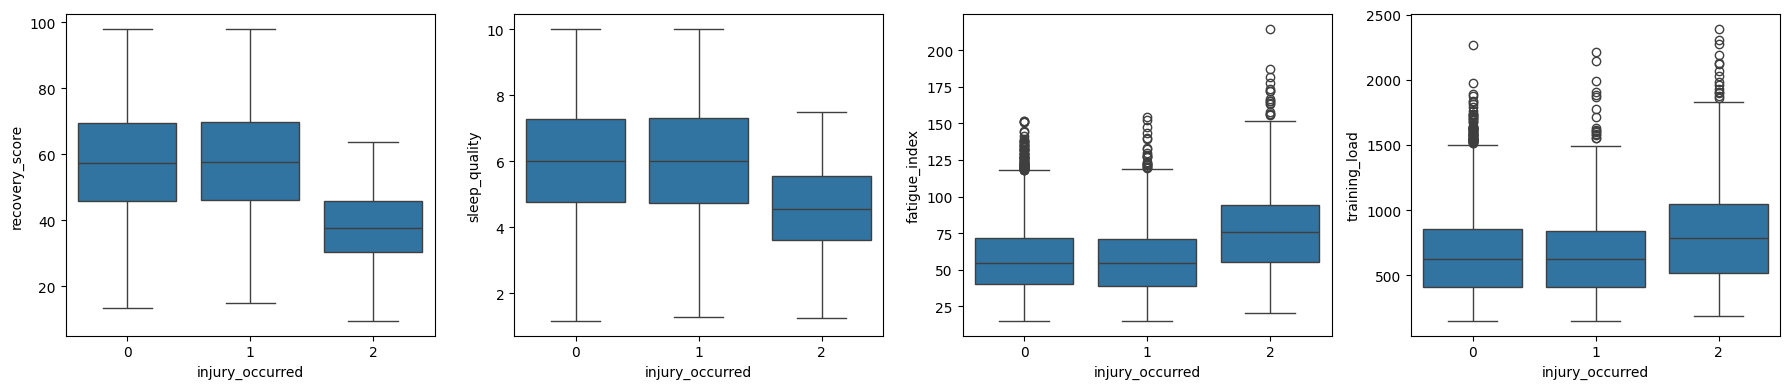

In [52]:
key_features = ['recovery_score', 'sleep_quality', 'fatigue_index', 'training_load']

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, key_features):
    sns.boxplot(x='injury_occurred', y=f, data=train, ax=ax)
plt.tight_layout()


In [53]:
train.groupby('injury_occurred')[key_features + ['heart_rate', 'muscle_activity', 'gait_speed']].mean().round(2)

,recovery_score,sleep_quality,fatigue_index,training_load,heart_rate,muscle_activity,gait_speed
injury_occurred,,,,,,,
0,58.14,6.02,56.72,647.05,72.72,248.82,1.87
1,58.15,6.02,56.09,641.59,73.04,248.44,1.85
2,38.26,4.58,76.30,798.93,72.38,248.04,1.88


Класс 2 (травма) существенно отличается: у травмированных заметно ниже восстановление и качество сна, выше усталость и нагрузка. Классы 0 и 1 **почти совпадают** - их ящики и средние неотличимы.

Разумно предположить, что классы 0 и 1 никакой классификатор с высокой точностью разделить не сможет.

Задача сводится к двухклассовой классификации (разделении, например, классов 1 и 2).

<Axes: xlabel='recovery_score', ylabel='fatigue_index'>

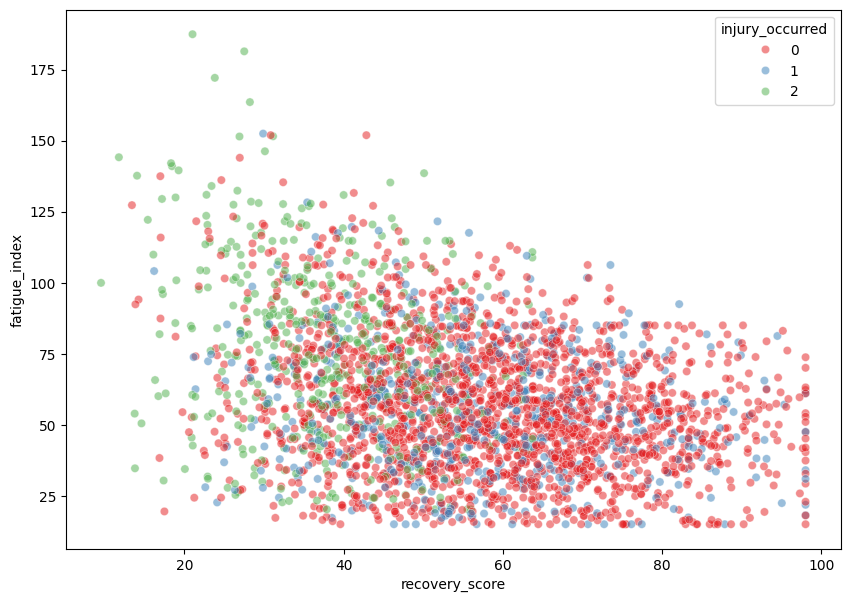

In [54]:
plt.figure(figsize=(10, 7))
sns.scatterplot(x='recovery_score', y='fatigue_index', hue='injury_occurred',
                data=train.sample(3000, random_state=0), alpha=0.5, palette='Set1')


Травмы (класс 2) сгущаются в левом верхнем углу (низкое восстановление, высокая усталость), но заметно перемешаны с остальными, а классы 0 и 1 перемешаны между собой (неразделимы).

## 4. Выбросы

Проверим значения, выходящие за диапазоны из README к датасету. Такие присутствуют у трех признаков:

In [55]:
readme_bounds = {'fatigue_index': (15, 85), 'training_load': (150, 1800), 'sleep_quality': (2, 10)}
for f, (lo, hi) in readme_bounds.items():
    print(f'{f:15s} вне [{lo}, {hi}]: {((train[f] < lo) | (train[f] > hi)).sum()}')

fatigue_index   вне [15, 85]: 1676
training_load   вне [150, 1800]: 30
sleep_quality   вне [2, 10]: 127


У `fatigue_index` таких значений особенно много (около 15%).

In [56]:
pd.DataFrame({
    'fatigue_index > 85': train.loc[train['fatigue_index'] > 85, 'injury_occurred'].value_counts(normalize=True),
    'вся выборка':       train['injury_occurred'].value_counts(normalize=True)}).round(3)

,fatigue_index > 85,вся выборка
injury_occurred,,
0,0.479,0.64
1,0.148,0.21
2,0.373,0.15


Среди сессий с высокой усталостью доля травм в 2.5 раза выше, чем в среднем. Видно, что это не выбросы, а информативные наблюдения, определяющие класс 2.


<Axes: xlabel='injury_occurred', ylabel='training_load'>

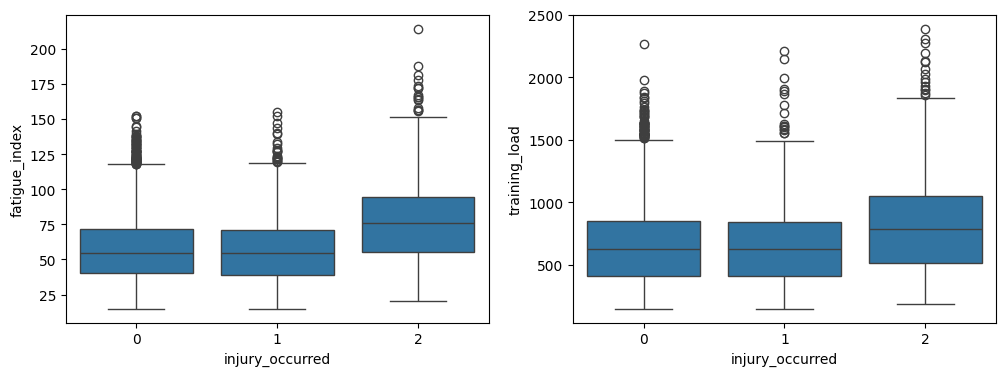

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='injury_occurred', y='fatigue_index', data=train, ax=axes[0])
sns.boxplot(x='injury_occurred', y='training_load', data=train, ax=axes[1])


Почти все кандидаты в выбросы приходятся на `fatigue_index` и `training_load`, что видно на боксплотах. На самом деле это хвосты распределений, которые и несут сигнал о травме.

В остальных признаках сильные отклонения обусловленны нормальным распределением медицинских данных, что является нормой.

## 5. Пропущенные значения

In [58]:
pd.DataFrame({'train': X_train.isna().sum(), 'test': X_test.isna().sum()}).query('train > 0 or test > 0')

,train,test
heart_rate,263,91
hydration_level,293,92
sleep_quality,374,119
muscle_activity,422,148
gait_speed,324,107
training_intensity,449,183


Пропуски есть в шести количественных признаках, от 2 до 4% в каждом. Заполняем их медианой. Медианы считаем только по обучающей выборке. Теми же значениями заполняем пропуски в тестовой. В категориальных признаках пропусков нет.

In [59]:
from sklearn.impute import SimpleImputer

num_features = X_train.select_dtypes('number').columns.tolist()
cat_features = ['sport_type', 'gender', 'playing_surface']

na_cols = X_train.columns[X_train.isna().any() | X_test.isna().any()]
report = pd.DataFrame({'train до': X_train[na_cols].isna().sum(),
                       'test до': X_test[na_cols].isna().sum()})

imp_num = SimpleImputer(strategy='median')
imp_num.fit(X_train[num_features])

X_train[num_features] = imp_num.transform(X_train[num_features])
X_test[num_features] = imp_num.transform(X_test[num_features])

report['медиана (train)'] = pd.Series(imp_num.statistics_, index=num_features)[na_cols].round(2)
report['train после'] = X_train[na_cols].isna().sum()
report['test после'] = X_test[na_cols].isna().sum()
report

,train до,test до,медиана (train),train после,test после
heart_rate,263,91,72.41,0,0
hydration_level,293,92,78.23,0,0
sleep_quality,374,119,5.75,0,0
muscle_activity,422,148,246.17,0,0
gait_speed,324,107,1.85,0,0
training_intensity,449,183,6.40,0,0


## 6. Категориальные признаки

`gender` приведем к бинарному (0 или 1). `sport_type` (4 значения) и `playing_surface` (5 значений) закодируем унитарно (one-hot).

In [60]:
from sklearn.preprocessing import OneHotEncoder

enc = OneHotEncoder(drop='if_binary', sparse_output=False)
enc.fit(X_train[cat_features])

dummies = pd.DataFrame(enc.transform(X_train[cat_features]),
                       columns=enc.get_feature_names_out(), index=X_train.index)
X_train = pd.concat((X_train.drop(cat_features, axis=1), dummies), axis=1)
dummies.columns.tolist()

['sport_type_Basketball',
 'sport_type_Other',
 'sport_type_Soccer',
 'sport_type_Track',
 'gender_Male',
 'playing_surface_0',
 'playing_surface_1',
 'playing_surface_2',
 'playing_surface_3',
 'playing_surface_4']

## 7. Нормализация

Для kNN нормализация обязательна, в нашем случае масштабы признаков отличаются на порядки (`stress_level` от 0.1 до 0.95, `step_count` от 2000 до 15000). Без масштабирования расстояние определялось бы почти целиком числом шагов, которое к тому же не связано с травмами. Используем стандартизацию (среднее 0, стандартное отклонение 1).

In [61]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_train.describe().loc[['mean', 'std']].round(2)

,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,cadence,...,sport_type_Basketball,sport_type_Other,sport_type_Soccer,sport_type_Track,gender_Male,playing_surface_0,playing_surface_1,playing_surface_2,playing_surface_3,playing_surface_4
mean,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,...,0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Те же преобразования (с параметрами, найденными по обучающей выборке) применяем к тестовой:

In [62]:
dummies = pd.DataFrame(enc.transform(X_test[cat_features]),
                       columns=enc.get_feature_names_out(), index=X_test.index)
X_test = pd.concat((X_test.drop(cat_features, axis=1), dummies), axis=1)

X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
X_test.shape, X_test.isna().sum().sum()

((3855, 33), np.int64(0))

## 8. Выбор модели

Выбранный метод - **k ближайших соседей**. Он непараметрический и не требует предположений о форме разделяющей границы. Признаков в датасете относительно немного, а данных достаточно, так что поиск соседей должен сработать быстро. Главный недостаток kNN - чувствительность к нерелевантным признакам: в расстоянии все признаки участвуют с одинаковым весом. Как показал первичный анализ, в нашем датасете полезных признаков, коррелирующих с целевым, всего 4. Поэтому рассмотрим два варианта: kNN на всех признаках и kNN только на четырех информативных.

Для сравнения в конце запустим логистическую регрессию (связь признаков с травмой монотонная, почти линейная) и random forest (автор датасета указывал как baseline).

Поскольку классы несбалансированы, будем дополнительно смотреть balanced accuracy (среднее значение полноты по классам) и полноту (recall) для класса 2: пропустить травму хуже, чем неверно ее спрогнозировать.

In [63]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import balanced_accuracy_score, recall_score

def evaluate(model, X_tr, X_te, name):
    y_tr_pred, y_te_pred = model.predict(X_tr), model.predict(X_te)
    return pd.Series({
        'err_train': np.mean(y_train != y_tr_pred),
        'err_test':  np.mean(y_test != y_te_pred),
        'bal_acc_test': balanced_accuracy_score(y_test, y_te_pred),
        'recall_injured_test': recall_score(y_test, y_te_pred, labels=[2], average=None)[0],
    }, name=name)

def plot_confusion(model, X_tr, X_te, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, X_, y_, part in [(axes[0], X_tr, y_train, 'train'), (axes[1], X_te, y_test, 'test')]:
        ConfusionMatrixDisplay(confusion_matrix(y_, model.predict(X_))).plot(ax=ax, colorbar=False, cmap='Blues')
        ax.set_title(f'{title}: {part}')
    plt.tight_layout()

results = pd.DataFrame()
results.loc['Всегда класс 0 (baseline)', ['err_train', 'err_test']] = \
    (np.mean(y_train != 0), np.mean(y_test != 0))
results

,err_train,err_test
Всегда класс 0 (baseline),0.360052,0.360052


In [64]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

results = pd.concat([results, evaluate(knn, X_train, X_test, 'kNN, k=5, все признаки').to_frame().T])
results

,err_train,err_test,bal_acc_test,recall_injured_test
Всегда класс 0 (baseline),0.360052,0.360052,NaN,NaN
"kNN, k=5, все признаки",0.305837,0.401038,0.363518,0.114187


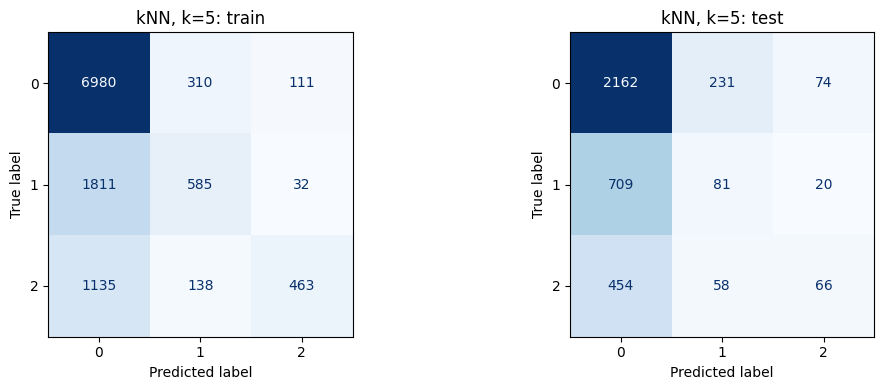

In [65]:
plot_confusion(knn, X_train, X_test, 'kNN, k=5')

При $k=5$ модель переобучена: ошибка на обучении около 31%, на тесте - около 40%, что хуже простого выбора класса 0 для всех записей. На матрице для теста видно, что классы 1 и 2 предсказываются почти наугад: соседей определяют несущественные признаки.

## 9. Подбор числа соседей

Подбираем $k$ по 5-кратной кросс-валидации на обучающей выборке.

({'n_neighbors': 35}, np.float64(0.35581495892779935))

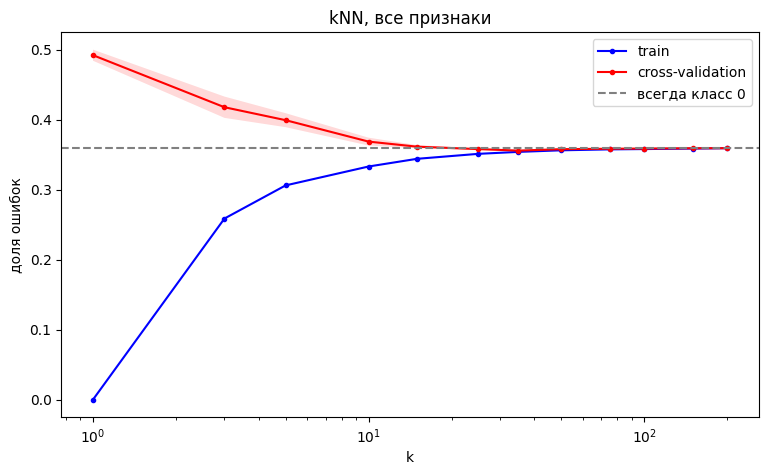

In [66]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

k_arr = [1, 3, 5, 10, 15, 25, 35, 50, 75, 100, 150, 200]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def knn_grid(X_tr):
    grid = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': k_arr},
                        cv=cv, scoring='accuracy', return_train_score=True, n_jobs=-1)
    grid.fit(X_tr, y_train)
    return grid

def plot_grid(grid, title):
    err_cv = 1 - grid.cv_results_['mean_test_score']
    err_tr = 1 - grid.cv_results_['mean_train_score']
    std_cv = grid.cv_results_['std_test_score']
    plt.figure(figsize=(9, 5))
    plt.plot(k_arr, err_tr, 'b.-', label='train')
    plt.plot(k_arr, err_cv, 'r.-', label='cross-validation')
    plt.fill_between(k_arr, err_cv - std_cv, err_cv + std_cv, alpha=0.15, facecolor='red')
    plt.axhline(np.mean(y_train != 0), color='gray', ls='--', label='всегда класс 0')
    plt.xscale('log')
    plt.xlabel('k')
    plt.ylabel('доля ошибок')
    plt.title(title)
    plt.legend()

grid_all = knn_grid(X_train)
plot_grid(grid_all, 'kNN, все признаки')
grid_all.best_params_, 1 - grid_all.best_score_

При $k=1$ ошибка на обучении нулевая (каждая точка сама себе сосед), с ростом $k$ модель сглаживается и ошибки на обучении и кросс-валидации сходятся. Но кривая кросс-валидации ни при каком $k$ не опускается заметно ниже базового уровня.

,err_train,err_test,bal_acc_test,recall_injured_test
Всегда класс 0 (baseline),0.360052,0.360052,NaN,NaN
"kNN, k=5, все признаки",0.305837,0.401038,0.363518,0.114187
"kNN, k=35, все признаки",0.354345,0.357717,0.343934,0.034602


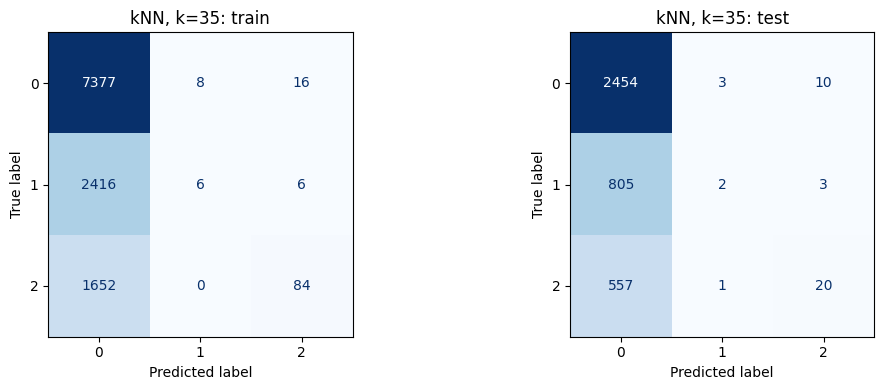

In [67]:
knn_all = KNeighborsClassifier(n_neighbors=grid_all.best_params_['n_neighbors']).fit(X_train, y_train)
results = pd.concat([results, evaluate(knn_all, X_train, X_test,
                     f"kNN, k={grid_all.best_params_['n_neighbors']}, все признаки").to_frame().T])
plot_confusion(knn_all, X_train, X_test, f"kNN, k={grid_all.best_params_['n_neighbors']}")
results

При оптимальном $k$ модель почти все относит к классу 0 и почти не находит травмы. Ошибка близка к базовой, то есть на всех признаках kNN толком ничему не научился.

### kNN на информативных признаках

Оставим только четыре признака, которые обсуждались на этапе анализа данных.

({'n_neighbors': 150}, np.float64(0.341980112408128))

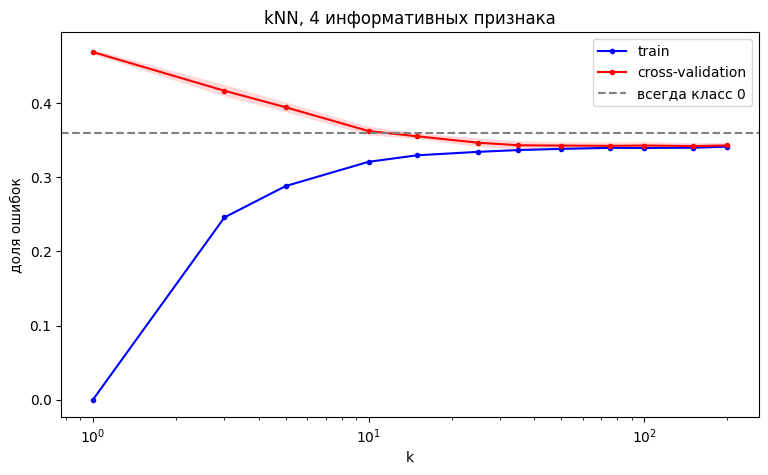

In [68]:
grid_key = knn_grid(X_train[key_features])
plot_grid(grid_key, 'kNN, 4 информативных признака')
grid_key.best_params_, 1 - grid_key.best_score_

,err_train,err_test,bal_acc_test,recall_injured_test
Всегда класс 0 (baseline),0.360052,0.360052,NaN,NaN
"kNN, k=5, все признаки",0.305837,0.401038,0.363518,0.114187
"kNN, k=35, все признаки",0.354345,0.357717,0.343934,0.034602
"kNN, k=150, 4 признака",0.339645,0.342412,0.417149,0.292388


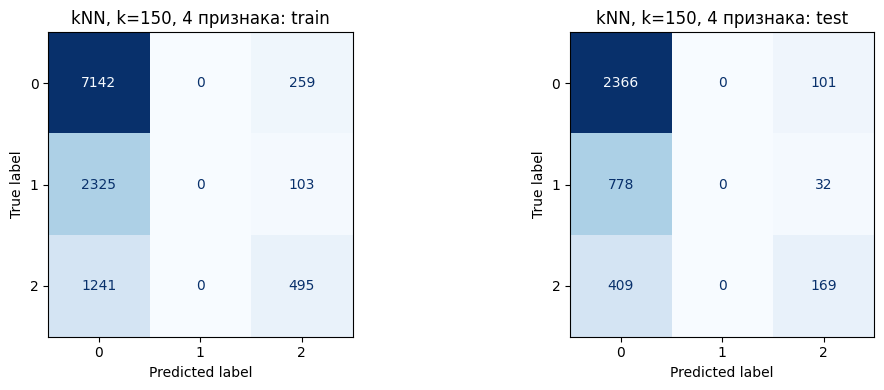

In [69]:
best_k = grid_key.best_params_['n_neighbors']
knn_key = KNeighborsClassifier(n_neighbors=best_k).fit(X_train[key_features], y_train)

results = pd.concat([results, evaluate(knn_key, X_train[key_features], X_test[key_features],
                     f'kNN, k={best_k}, 4 признака').to_frame().T])
plot_confusion(knn_key, X_train[key_features], X_test[key_features], f'kNN, k={best_k}, 4 признака')
results

In [70]:
print(classification_report(y_test, knn_key.predict(X_test[key_features]),
                            target_names=['Healthy', 'Low Risk', 'Injured'], zero_division=0))

              precision    recall  f1-score   support

     Healthy       0.67      0.96      0.79      2467
    Low Risk       0.00      0.00      0.00       810
     Injured       0.56      0.29      0.38       578

    accuracy                           0.66      3855
   macro avg       0.41      0.42      0.39      3855
weighted avg       0.51      0.66      0.56      3855



После отбора признаков kNN начал находить травмы: полнота по классу 2 выросла с 3% до 29%, balanced accuracy - с 0.34 до 0.42, ошибка опустилась ниже базового уровня.

Оптимальное $k$ получилось большим: граница между классами сильно размыта, и нужно усреднять ее по многим соседям. По графику видно, что примерно с $k=35$ ошибка выходит на плато, и формально лучшее $k=150$ от соседних значений почти не отличается.

Класс 1 модель не предсказывает вообще, и это ожидаемо: по признакам он неотличим от класса 0, и отнести к нему сессию можно только случайно, что невыгодно с точки зрения стоимости ошибки.

### Сравнение с другими моделями

Логистическая регрессия и random forest встроенно справляются с нерелевантными признаками (малые веса и редкие разбиения по шумовым признакам соответственно), поэтому обучаем их на всех признаках.

In [71]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42).fit(X_train, y_train)

for model, name in [(logreg, 'Логистическая регрессия'), (rf, 'random forest')]:
    results = pd.concat([results, evaluate(model, X_train, X_test, name).to_frame().T])
results.round(3)

,err_train,err_test,bal_acc_test,recall_injured_test
Всегда класс 0 (baseline),0.360,0.360,NaN,NaN
"kNN, k=5, все признаки",0.306,0.401,0.364,0.114
"kNN, k=35, все признаки",0.354,0.358,0.344,0.035
"kNN, k=150, 4 признака",0.340,0.342,0.417,0.292
Логистическая регрессия,0.326,0.320,0.470,0.453
random forest,0.182,0.333,0.432,0.330


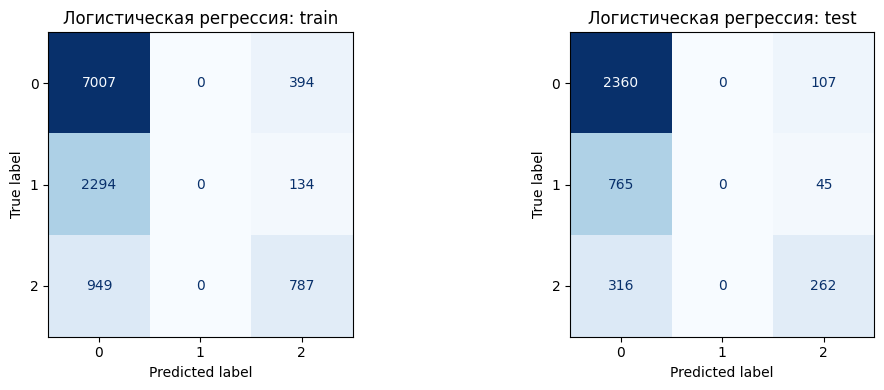

In [72]:
plot_confusion(logreg, X_train, X_test, 'Логистическая регрессия')

Text(0.5, 1.0, 'Важность признаков (random forest)')

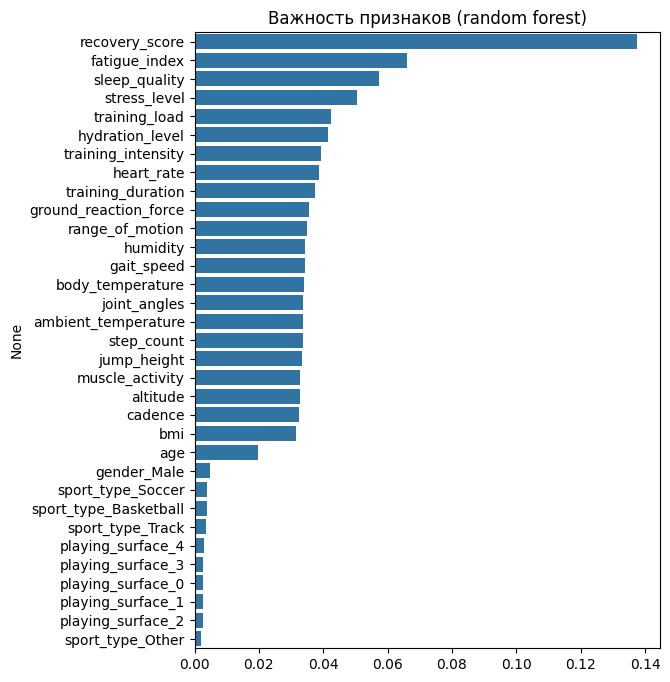

In [73]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(6, 8))
sns.barplot(x=importances.values, y=importances.index, orient='h')
plt.title('Важность признаков (random forest)')


Лучшие результаты у логистической регрессии: ошибка 32%, находит 45% травм, ошибки на обучении и тесте совпадают (переобучения нет). Лес переобучается (18% на обучении против 33% на тесте). kNN даже после отбора признаков отстает от обоих. Важность признаков в лесу подтверждает первичный анализ: с большим отрывом лидируют те же четыре признака, остальные примерно одинаково малы.

Все модели упираются в предельное значение в 32–34% ошибок (при базовых 36%). Это не недостаток методов, а свойство данных: около 21% объектов (класс 1) в принципе неотличимы от класса 0.

Заметим, что чаще важнее точно предсказать травму, чем минимизировать общую долю ошибок. Логистическая регрессия с `class_weight='balanced'` штрафует ошибки на редких классах сильнее:

,err_train,err_test,bal_acc_test,recall_injured_test
Всегда класс 0 (baseline),0.360,0.360,NaN,NaN
"kNN, k=5, все признаки",0.306,0.401,0.364,0.114
"kNN, k=35, все признаки",0.354,0.358,0.344,0.035
"kNN, k=150, 4 признака",0.340,0.342,0.417,0.292
Логистическая регрессия,0.326,0.320,0.470,0.453
random forest,0.182,0.333,0.432,0.330
"Логистическая регрессия, balanced",0.534,0.529,0.546,0.848


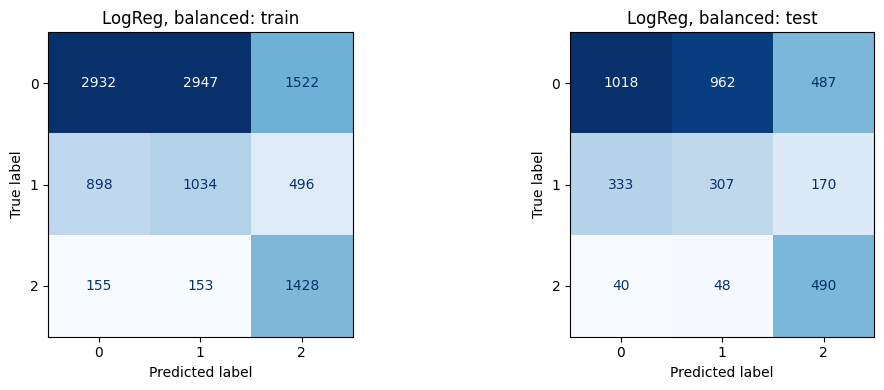

In [74]:
logreg_bal = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train, y_train)
results = pd.concat([results, evaluate(logreg_bal, X_train, X_test,
                     'Логистическая регрессия, balanced').to_frame().T])
plot_confusion(logreg_bal, X_train, X_test, 'LogReg, balanced')
results.round(3)

Общая ошибка выросла до 53%, зато находит уже около 85% травм вместо 45%, и balanced accuracy выше. Платим за это ложноположительными срабатываниями. Выбор модели зависит от цели классификации.

## 10. Выводы

1. **Данные.** 15 420 сессий, 26 содержательных признаков, около 3% пропусков (заполняются медианой), данные физически корректны.

2. **Существенная корреляция с целевым есть только у четырех признаках:** качество сна и восстановление (ниже → выше), усталость и тренировочная нагрузка (выше → выше).

3. **Класс «Low Risk» неотличим от «Healthy»** ни по одному признаку. Фактически решается задача двухклассовой классификации.

4. **kNN** на всех признаках не лучше константного прогноза (при $k=5$ даже хуже) из-за большого числа несущественных признаков. После отбора 4 информативных признаков и подбора $k$ по кросс-валидации ($k=150$) ошибка падает до 34%, а полнота по травмам растет с 3% до 29%.

5. **Лучший результат** у логистической регрессии (ошибка 32%, найдено 45% травм): она устойчива к шумовым признакам и не переобучается, а связь признаков с риском в данных почти линейная. Если важнее не пропустить травму, лучше взять вариант с `class_weight='balanced'`: он находит около 85% травм ценой большего числа ложных тревог.